# Week 6 Homework: Your Answers vs. Your Vibe-Coded Dashboard

**Week 4 dashboard link:** (https://2026-ds-630-nabil-said.streamlit.app/)

---

Two weeks ago you vibe-coded a MovieLens dashboard before you had the tools to judge it. Since then you've had the stats lecture (Week 5) and this week's EDA lecture. Now you do it the real way: answer the same 4 questions yourself, by hand, then audit the dashboard against your own work.

**Ground rules**

- 🚫 **No AI for code or answers in Parts 1 and 2.** Lecture notebooks, pandas/seaborn docs, Google, and Stack Overflow are all fair game. Write Part 3 in your own words too.
- 🔒 **Lock in before you peek.** Finish Parts 1 and 2 (answers written down) *before* you open your dashboard. If you look first, you'll anchor on its numbers and the comparison is worthless.
- 🔢 **Show your numbers.** Every answer needs actual values (counts, averages, titles), not just a vibe.
- ✏️ Written answers go in markdown cells (double-click to edit, Shift+Enter to render). Most are 2 to 4 sentences. Short and specific beats long and vague.

## The data

`movie_ratings.csv` has one row per rating: 100,000 ratings from 943 users on 1,682 movies.

- `user_id`, `movie_id`: who rated, which movie
- `rating`: 1 to 5 stars
- `timestamp`, `rating_year`: when the rating was given
- `age`, `gender`, `occupation`, `zip_code`: the rater
- `title`: movie title, with release year in parentheses
- `year`, `decade`: the movie's release year and decade
- `genres`: all of the movie's genres in one string, separated by the pipe character (a movie can have several)

## Setup

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Works whether this notebook sits in the week folder or inside exercise/
data_path = next(p for p in ["data/movie_ratings.csv", "../data/movie_ratings.csv"] if Path(p).exists())
df = pd.read_csv(data_path)
df.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,title,year,decade,genres,rating_year
0,196,242,3,1997-12-04 15:55:49,49,M,writer,55105,Kolya (1996),1996.0,1990.0,Comedy,1997
1,186,302,3,1998-04-04 19:22:22,39,F,executive,00000,L.A. Confidential (1997),1997.0,1990.0,Crime|Film-Noir|Mystery|Thriller,1998
2,22,377,1,1997-11-07 07:18:36,25,M,writer,40206,Heavyweights (1994),1994.0,1990.0,Children|Comedy,1997
3,244,51,2,1997-11-27 05:02:03,28,M,technician,80525,Legends of the Fall (1994),1994.0,1990.0,Drama|Romance|War|Western,1997
4,166,346,1,1998-02-02 05:33:16,47,M,educator,55113,Jackie Brown (1997),1997.0,1990.0,Crime|Drama,1998


---
# Part 1: Methodology

## 1.1 Know your data first

Before answering anything, check what you're working with: shape, column types, missing values, duplicate rows, and the range of the numeric columns.

In [5]:
print("shape:", df.shape)
print("----------------------")
df.info()

print("----------------------")
print("missing/null:")
print(df.isna().sum())

print("----------------------")
print("duplicates:", df.duplicated().sum())

print("----------------------")
display(df.describe())

print("----------------------")
df = df.dropna(subset=['year', 'decade'])

shape: (100000, 13)
----------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   user_id      100000 non-null  int64  
 1   movie_id     100000 non-null  int64  
 2   rating       100000 non-null  int64  
 3   timestamp    100000 non-null  object 
 4   age          100000 non-null  int64  
 5   gender       100000 non-null  object 
 6   occupation   100000 non-null  object 
 7   zip_code     100000 non-null  object 
 8   title        100000 non-null  object 
 9   year         99970 non-null   float64
 10  decade       99970 non-null   float64
 11  genres       100000 non-null  object 
 12  rating_year  100000 non-null  int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 9.9+ MB
----------------------
missing/null:
user_id         0
movie_id        0
rating          0
timestamp       0
age             0
gender       

,user_id,movie_id,rating,age,year,decade,rating_year
count,100000.00000,100000.000000,100000.000000,100000.000000,99970.000000,99970.000000,100000.000000
mean,462.48475,425.530130,3.529860,32.969850,1987.748224,1982.780134,1997.471010
std,266.61442,330.798356,1.125674,11.562623,14.140014,13.820687,0.499161
min,1.00000,1.000000,1.000000,7.000000,1922.000000,1920.000000,1997.000000
25%,254.00000,175.000000,3.000000,24.000000,1986.000000,1980.000000,1997.000000
50%,447.00000,322.000000,4.000000,30.000000,1994.000000,1990.000000,1997.000000
75%,682.00000,631.000000,4.000000,40.000000,1996.000000,1990.000000,1998.000000
max,943.00000,1682.000000,5.000000,73.000000,1998.000000,1990.000000,1998.000000


----------------------


**Data notes:** The data is comprised of 100,000 rows and 13 columns, and there are no duplicate rows. The year and decade columns each are missing 30 values. Ratings, ages, release years are all in a realistic range. decided to drop the missing years and decades since it only makes up about 0.03% of our data and wouldnt sway any of the answers.

## 1.2 Decide before you chart

**Q1 Genre breakdown**
- What you have to decide: What am I counting, ratings or movies? How do I handle movies that have several genres?
- My choice: Count each movie once using movie ID then count. A movie can count in multiple genres.
- Why: The question asks about movies and genra, not how many ratings they got.

**Q2 Genre satisfaction**
- What you have to decide: "Average rating" of what? How do I treat genres that have very little data?
- My choice: Average all ratings in each genre and show the out of how many ratings. Keep every category, since only `unknown` is the only one with 10 ratings.
- Why: This gives each rating equal weight

**Q3 Ratings over time**
- What you have to decide: Is every year backed by the same amount of data? What do I do with movies that have no release year?
- My choice: Group by release year and show the mean and count. We already dropped the 30 ratings with no year because they were insignificant.
- Why: There is bothing we can do about the data with the missing years and it wont matter anyway.

**Q4 Best movies**
- What you have to decide: What is a movie's rating (the mean of what)? Is "at least 50" ≥ or >? What if there's a tie?
- My choice: Average ratings for each movie ID. Use >= 50, and >= 150. Sort ties by more ratings.
- Why: deals with ties in a clean non misleading way

---
# Part 2: Results (by hand, no AI)

Answer each question with a chart or table **and** a written answer with real numbers. Pick the chart type yourself and be ready to defend it in Part 3. Add as many code cells as you need.

## Q1. Genre breakdown

**What's the distribution of genres among the movies that were rated?**

<details>
<summary>Stuck on movies with several genres? Hint</summary>

`genres` is one string like `Crime|Film-Noir|Mystery|Thriller`. To get one row per genre:

```python
genre_df = df.assign(genre=df['genres'].str.split('|')).explode('genre')
```

Heads up: after this, a movie with 3 genres takes up 3 rows. Think about what that does to anything you count or average. Exploding is fine for "how often does a genre show up", but be careful calling the result "market share" (the percentages add up to more than 100%).
</details>

genre
Drama          724
Comedy         505
Thriller       251
Action         251
Romance        247
Adventure      135
Children       121
Crime          109
Sci-Fi         101
Horror          92
War             71
Mystery         61
Musical         56
Documentary     48
Animation       41
Western         27
Film-Noir       24
Fantasy         22
unknown          1
Name: count, dtype: int64

----------------------


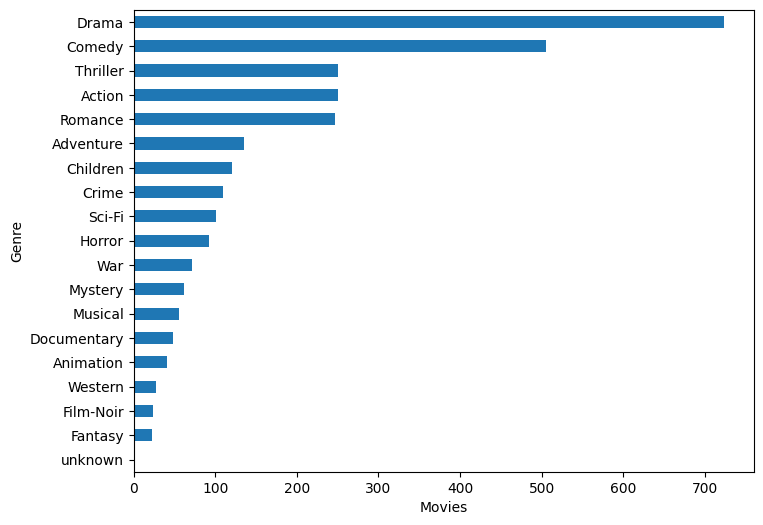

In [11]:
movies = df.drop_duplicates('movie_id').copy()
movies['genre'] = movies['genres'].str.split('|')
movie_genres = movies.explode('genre')

genre_counts = movie_genres['genre'].value_counts()
display(genre_counts)

print("----------------------")

genre_counts.sort_values().plot(kind='barh', figsize=(8, 6))
plt.xlabel('Movies')
plt.ylabel('Genre')
plt.show()

**My answer:** Drama leads with 725 movies, then Comedy with 505. Drama has 220 more movies than Comedy. Action and Thriller are tied at 251 each. Fantasy is the last genra other than 'unknown' with 22 movies.

## Q2. Genre satisfaction

**Which genres have the highest average rating? Which have the lowest?**

Show how much data is behind each average (for example, the count next to it). An average of 10 ratings and an average of 10,000 ratings are not the same kind of evidence.

In [12]:
genre_df = df.copy()
genre_df['genre'] = genre_df['genres'].str.split('|')
genre_df = genre_df.explode('genre')

genre_ratings = genre_df.groupby('genre')['rating'].agg(['mean', 'count'])
genre_ratings = genre_ratings.sort_values('mean', ascending=False)
print(genre_ratings)

                 mean  count
genre                       
Film-Noir    3.921523   1733
War          3.815812   9398
Documentary  3.688172    744
Drama        3.687397  39894
Mystery      3.638132   5245
Crime        3.632278   8055
Romance      3.621705  19461
Western      3.613269   1854
Animation    3.579883   3599
Sci-Fi       3.560723  12730
Musical      3.521397   4954
Thriller     3.509007  21872
Adventure    3.503527  13753
Action       3.480245  25589
Comedy       3.394073  29832
Children     3.354654   7176
Horror       3.290389   5317
Fantasy      3.215237   1352
unknown      1.000000      1


**My answer:** Film-Noir is highest at 3.922 from 1,733 ratings, followed by War at 3.816 from 9,398. Fantasy       again is the category is lowest at 3.215 from 1,352 ratings, followed by Horror at 3.290 from 5,317.

## Q3. Ratings over time

**How has the mean rating changed across movie release years?**

Show how many ratings each year is based on, alongside the trend.

            mean  count
year                   
1922.0  3.555556     54
1926.0  3.000000      2
1930.0  3.777778     18
1931.0  4.000000     44
1932.0  3.833333     12
...          ...    ...
1994.0  3.420080   9034
1995.0  3.414642  12389
1996.0  3.311086  18744
1997.0  3.312467  15384
1998.0  3.297297    851

[71 rows x 2 columns]
Mean rating by movie release year


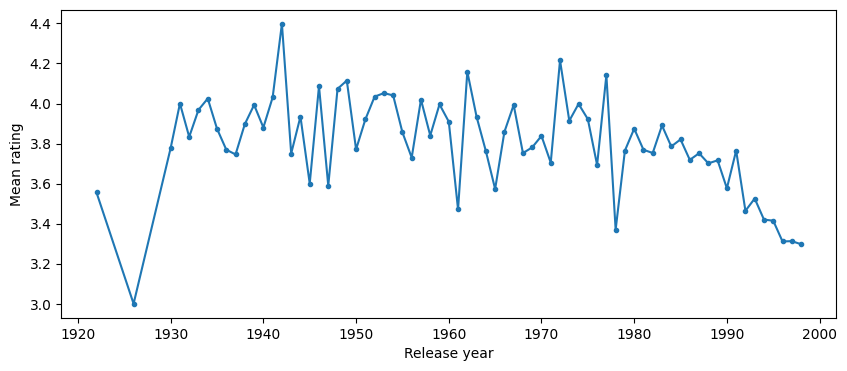

Number of ratings by movie release year


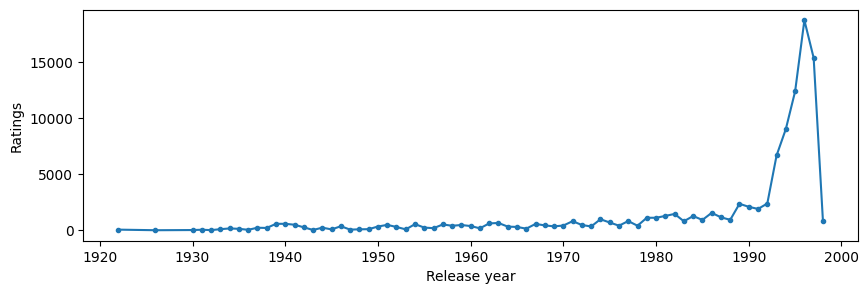

In [23]:
year_df = df.copy()
year_ratings = year_df.groupby('year')['rating'].agg(['mean', 'count'])
print(year_ratings)

year_ratings['mean'].plot(kind='line', marker='.', figsize=(10, 4))
print('Mean rating by movie release year')
plt.xlabel('Release year')
plt.ylabel('Mean rating')
plt.show()
year_ratings['count'].plot(kind='line', marker='.', figsize=(10, 3))
print('Number of ratings by movie release year')
plt.xlabel('Release year')
plt.ylabel('Ratings')
plt.show()

**My answer:** Older release years (1980 and before) generally score better, but the line jumps around. For example, 1942 averages 4.398 from 261 ratings, while 1997 averages 3.312 from 15,384. The evidence is not strong enough to say either any year or period outperforms the other

## Q4. Best movies, with a floor

**What are the 5 best-rated movies that have at least 50 ratings? What changes if you raise the floor to 150?**

In [31]:
movie_ratings = df.groupby(['movie_id', 'title'])['rating'].agg(['mean', 'count'])
movie_ratings = movie_ratings.sort_values(['mean', 'count'], ascending=[False, False])

top_50 = movie_ratings[movie_ratings['count'] >= 50].head(5)
top_150 = movie_ratings[movie_ratings['count'] >= 150].head(5)
print('At least 50 ratings:')
print(top_50)
print('At least 150 ratings:')
print(top_150)

At least 50 ratings:
                                                                 mean  count
movie_id title                                                              
408      Close Shave, A (1995)                               4.491071    112
318      Schindler's List (1993)                             4.466443    298
169      Wrong Trousers, The (1993)                          4.466102    118
483      Casablanca (1942)                                   4.456790    243
114      Wallace & Gromit: The Best of Aardman Animation...  4.447761     67
At least 150 ratings:
                                               mean  count
movie_id title                                            
318      Schindler's List (1993)           4.466443    298
483      Casablanca (1942)                 4.456790    243
64       Shawshank Redemption, The (1994)  4.445230    283
603      Rear Window (1954)                4.387560    209
12       Usual Suspects, The (1995)        4.385768    267


**My answer:**

At least 50 ratings:
Close Shave, A (1995) | 4.491 
Schindler's List (1993) | 4.466 
Wrong Trousers, The (1993) | 4.466 
Casablanca (1942) | 4.457 
Wallace & Gromit: The Best of Aardman Animation (1996) | 4.448 

At least 150 ratings:
Schindler's List (1993) | 4.466 
Casablanca (1942) | 4.457 | 243 
Shawshank Redemption, The (1994) | 4.445 
Rear Window (1954) | 4.388 
Usual Suspects, The (1995) | 4.386 

A Close Shave, The Wrong Trousers, and Wallace & Gromit drop out because they have fewer than 150 ratings. The Shawshank Redemption, Rear Window, and The Usual Suspects move in. The averages did not change, the cutoff for the count changed. Smaller samples to bigger sample changes a lot of the the ranking. 

> 🔒 **Stop here.** Parts 1 and 2 should be completely filled in before you open your dashboard.

---
# Part 3: Analysis

## 3.1 How the dashboard got built


**Prompt 1**
- What I asked: here is an assignement I have to build a dashboard on streamlit, lets create a plan on how to build it (pasted assignment)
- AI's first attempt: came up with a plan and set a list of thing that needed to be done
- What I changed (or accepted without checking): not much I told it to keep the python readable so I can recheck its work

**Prompt 2**
- What I asked: change some of the styling
- AI's first attempt: refactored some of the styling
- What I changed (or accepted without checking): just accepted changes

## 3.2 Compare the answers

The dashboard defaults to all genres and the full release-year range.

**Q1**
- Dashboard says: Drama 725 movies, Comedy 505, and Action and Thriller 251 each.
- I say: Drama has 725, Comedy 505, and Action and Thriller 251 each.
- Same? yes.
- If different, why? No difference in the counts. keeps all genras and ranking is the same

**Q2**
- Dashboard says: Film-Noir is highest (3.92); `unknown` is lowest (3.20).
- I say: Film-Noir is highest (3.922, 1,733 ratings); `unknown` is lowest (3.200, 10 ratings).
- Same? mostly.
- If different, why? I didint round my numbers and the 'unkonwn' value might be because I dropped some rows

**Q3**
- Dashboard says: Mean rating by movie release year, shown as a plot.
- I say: Older release years generally score higher, but the rating counts vary a lot.
- Same? mostly.
- If different, why? The app and my calculation group by release year and show a similar trend.

**Q4**
- Dashboard says: top five 50 ratings and top 5 150 ratings.
- I say: Same top-five lists and ratings.
- Same? yes.
- If different, why? no diffrence

**When numbers differ, check these first.** Most mismatches come from one of these:

- Counting **ratings** vs. counting **movies**
- One row per rating vs. **one row per rating per genre** (after exploding)
- **Mean of all ratings** vs. the mean of each movie's average
- "At least 50" as ≥ vs. >, or applying the floor before vs. after another step
- What happened to movies with a **missing year**
- Genres with **tiny sample sizes** left in or filtered out

**Two-question explanation:** For Q2, the app's `unknown` has only 10 ratings, while mine has only 1 and that is because AI retained the 30 missing values for that question while I dropped them. For Q3, the chart shows the release-year means but no chart for counts so when reading it could be a little misleading.

## 3.3 Chart choices

**Q1**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q2**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q3**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

**Q4**
- Chart the dashboard used:
- Chart I used:
- Which communicates the answer better, and why?

Use what you learned about chart choice and misleading charts (Week 5) and this week's lecture. Is it sorted? Are the labels readable? Are the axes honest? Does it show how much data is behind each number?

## 3.4 What can this data actually tell you?

**Answer at least 3 of these 5**, using your own results as evidence.

**1. Who is in this data?** Check the fewest and the most ratings any single user has given (`df.groupby('user_id').size()`), and look at `rating_year`. What kind of person ends up in a dataset like this, and who is missing? How might that tilt your Q2 answer? *(Week 5: sampling bias)*

**2. How sure are you about the bottom genre?** Take the lowest-rated genre from your Q2. How many ratings *and* how many distinct movies is it built on? Estimate a rough 95% interval: mean ± 1.96 × std / √n. Would you bet it's truly the worst genre? *(Week 5: standard error and confidence intervals. Also ask yourself: are 5,000 ratings of the same handful of movies really 5,000 independent pieces of evidence? Remember the one-row-per-model lesson from last week's homework.)*

**3. What can Q3 really say about time?** How many different values does `rating_year` have? So can this data tell you whether people's taste changed over time? What does your Q3 trend actually describe instead? Why might an old movie in this dataset score higher than a recent one? *(Think: who rates a 1940s film in 1997, and which old movies are even in the data?)*

**4. Does "average" depend on how you average?** Recompute Q2 two ways: (a) average over all ratings, (b) average each movie first, then average the movies within each genre. Does the top genre change? "Which genre do *people* like most?" and "which genre has the best *movies*?" are different questions. *(Week 5: confounding, Simpson's paradox)*

**5. Deployment risk.** A studio exec uses your dashboard to decide which genre to green-light. What's the most misleading conclusion they could draw from one of your charts? Write the one-line caveat you'd put under that chart.

**✏️ Your answers:** _(label each one with its number)_

## 3.5 Verdict

**Where I'd override the AI** (something it got wrong, hid, or did poorly, and what your version did better):

**Where the AI held up** (something it did well, or a choice you doubted at first that turned out right):

**One sentence:** looking back at both weeks, who was driving, you or the AI, and when?

---
## Optional stretch

Only if you want more practice:

- Pick 4 genres. How does the mean rating change as viewer age increases? (Try more than 4 and see which genres make the most interesting chart.)
- Plot number of ratings vs. mean rating for each movie. Do the most-rated movies get higher ratings? Is there a correlation? *(Week 5: correlation vs. causation)*

---
## Before you submit

- [ ] Copy this notebook into the `exercise/` folder and rename it `Firstname_Lastname_week_06_exercise.ipynb`
- [ ] **Kernel → Restart & Run All** and make sure it runs top to bottom with your charts showing
- [ ] Every ✏️ cell and every fill-in line is filled in
- [ ] Open a PR from your fork, same as every other week